# Modelagem preditiva da produtividade da safra de soja com uso de aprendizado de máquina e dados agrometeorológicos — Modelagem (Etapa 5: clima do NASA POWER)

**Integrantes:**
**Orientador:**

**Síntese do conteúdo deste arquivo:** até a Etapa 4, o clima de cada município vinha da estação automática do INMET mais próxima, e cerca de metade dos pares município–safra com rendimento ficava fora do modelo por falta de dado da estação. Este notebook usa o clima diário do **NASA POWER** (grade de 0,5° × 0,625°, sem falhas, baixado por `dataset/baixar_nasa_power.py`) para (1) calcular as mesmas variáveis climáticas das Etapas 2 e 4 (chuva por subperíodo, seca, calor, umidade mínima e balanço hídrico) por célula da grade e safra; (2) **comparar NASA POWER × INMET** nas estações; e (3) treinar os modelos F e H2 (e o Gradient Boosting) com o clima do NASA POWER em três cenários — nas mesmas linhas do INMET, em todas as linhas e só nas linhas novas —, com as mesmas duas validações da Etapa 4; e (4) testar combinações de F e H2 (média, Ridge, F + um limiar) e escolher o modelo final. O patamar usa só as safras publicadas na data da previsão (até Y−2), como na Etapa 4. As variáveis por célula e safra são salvas em `dataset/processed/clima_nasa_power_celula_safra.csv`.

| Data       | Autor           | Descrição                                                                 |
|------------|-----------------|-----------------------------------------------------------------------------|
| 2026-10-23 |                 | Criação do notebook — variáveis climáticas do NASA POWER, comparação com o INMET e modelos F, H2 e Gradient Boosting com cobertura ampliada |
| 2026-10-23 |                 | Testadas combinações de F e H2 (média, Ridge, F + um limiar); novo modelo final FL (F + limiar de déficit) usado nas análises por safra, secas, região e coeficientes |
| 2026-10-26 |                 | Patamar e média histórica passam a usar só as safras publicadas pela PAM/IBGE até Y−2 (`DEFASAGEM_PUBLICACAO`), como na Etapa 4; primeira safra passa a 2006. Saídas e conclusões (seção 12) precisam ser regeradas, e a escolha do FL, reconfirmada |

## 1. Imports e configuração

Mesmas convenções e parâmetros das Etapas 2 e 4 (limiares de dia seco e de calor, CAD de
75 mm, limiares de seca extrema no percentil 20 do treino).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RAW = "../dataset/raw"
PROCESSED = "../dataset/processed"

ANO_CORTE = 2020          # corte temporal: treino até 2020, teste 2021-2025
DEFASAGEM_PUBLICACAO = 2  # em março de Y, a última safra publicada pela PAM/IBGE é Y-2
PRIMEIRA_SAFRA = 2006     # primeira safra com 5 safras publicadas para o patamar
SEED = 42
LIMIAR_SECO_MM = 1.0      # dia seco: chuva < 1 mm
LIMIAR_CALOR_C = 32.0     # dia de calor: temperatura máxima >= 32 °C
CAD_MM = 75               # capacidade de água disponível no solo
PERCENTIL_LIMIAR = 0.2    # limiares de seca extrema: 20% mais secos do treino
PASSO_LAT, PASSO_LON = 0.5, 0.625   # tamanho da célula da grade do NASA POWER

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Ambiente pronto.")

## 2. Dados

- NASA POWER diário por célula da grade (out–mai, 2000–2025) e a tabela que liga cada
  município à célula que o contém (`dataset/baixar_nasa_power.py`);
- painel município–safra (rendimento e ONI);
- clima por subperíodo (Etapa 2) e balanço hídrico (Etapa 4) das estações do INMET, para
  a comparação e para o cenário de referência.

In [2]:
def chave_celula(lat, lon):
    return lat.map("{:.3f}".format) + "_" + lon.map("{:.4f}".format)


power = pd.read_csv(f"{RAW}/nasa_power_rs_2000_2025.csv", parse_dates=["data"])
mapa = pd.read_csv(f"{RAW}/nasa_power_celulas_municipios_rs.csv")
power["celula"] = chave_celula(power["lat_celula"], power["lon_celula"])
mapa["celula"] = chave_celula(mapa["lat_celula"], mapa["lon_celula"])

painel = pd.read_csv(f"{PROCESSED}/painel_municipio_safra.csv")
clima_inmet = (pd.read_csv(f"{PROCESSED}/clima_subperiodos_estacao_safra.csv")
               .merge(pd.read_csv(f"{PROCESSED}/balanco_hidrico_estacao_safra.csv"),
                      on=["codigo_estacao", "ano_safra"], how="outer"))
regioes = pd.read_csv(f"{RAW}/ibge_municipios_rs_regioes.csv",
                      usecols=["codigo_ibge_municipio", "mesorregiao"])
regioes["mesorregiao"] = regioes["mesorregiao"].str.replace(" Rio-grandense", "")

ALVO = "rendimento_kg_ha"
ONI = "oni_media_safra"
CLIMA = ["chuva_out_nov", "chuva_dez_fev", "chuva_mar", "seca_max_dez_fev",
         "dias_calor_dez_fev", "tmax_dez_fev", "urmin_dez_fev"]
VAR_HIDRICO = ["deficit_dez_fev", "balanco_dez_fev", "eto_dez_fev"]
com_rendimento = painel.dropna(subset=[ALVO])

print(f"NASA POWER: {len(power):,} dias-célula | {power['celula'].nunique()} células | "
      f"{power['data'].min():%Y-%m-%d} a {power['data'].max():%Y-%m-%d}")
print(f"Valores ausentes no NASA POWER: {power.isna().sum().sum()}")
print(f"Municípios por célula: mediana {mapa.groupby('celula').size().median():.0f}, "
      f"máximo {mapa.groupby('celula').size().max()}")

NASA POWER: 550,275 dias-célula | 87 células | 2000-01-01 a 2025-12-31
Valores ausentes no NASA POWER: 0
Municípios por célula: mediana 2, máximo 33


## 3. Variáveis climáticas por célula e safra

Mesmas regras das Etapas 2 e 4: out–dez contam para a safra do ano seguinte; subperíodos
out–nov, dez–fev, mar e abr–mai; dia seco com chuva < 1 mm; dia de calor com máxima
≥ 32 °C. O NASA POWER não tem falhas, então não há filtro de cobertura mínima.

**Umidade relativa mínima.** O NASA POWER fornece só a umidade relativa média, mas a
mínima pode ser estimada pelo método da FAO-56 (Allen et al., 1998, eq. 11 e 14): a
pressão de vapor do ar, dada pelo ponto de orvalho, dividida pela pressão de saturação na
temperatura máxima do dia:

URmín ≈ 100 × e°(T_orvalho) / e°(T_máx), com e°(T) = 0,6108 · exp(17,27·T / (T + 237,3)).

**Balanço hídrico.** Mesmo método da Etapa 4: ETo de Hargreaves-Samani com a radiação no
topo da atmosfera calculada pela latitude da célula, e modelo de balde com CAD de 75 mm,
cheio em 1º de outubro.

In [3]:
def pressao_saturacao(t):
    return 0.6108 * np.exp(17.27 * t / (t + 237.3))


power["urmin"] = (100 * pressao_saturacao(power["tdew_c"])
                  / pressao_saturacao(power["tmax_c"])).clip(upper=100)
mes = power["data"].dt.month
power["ano_safra"] = power["data"].dt.year + (mes >= 10)
power["subperiodo"] = pd.cut(mes.where(mes >= 4, mes + 12), bins=[3, 5, 9, 11, 14, 15],
                             labels=["abr_mai", "fora", "out_nov", "dez_fev", "mar"])
power = power[power["ano_safra"].between(2001, 2025)].copy()
power["calor"] = power["tmax_c"] >= LIMIAR_CALOR_C

chaves = [power["celula"], power["ano_safra"], power["subperiodo"]]
g = power.groupby(chaves, observed=True)
sub = pd.DataFrame({"chuva": g["chuva_mm"].sum(), "tmax": g["tmax_c"].mean(),
                    "urmin": g["urmin"].mean(), "dias_calor": g["calor"].sum()})

# Maior sequência de dias secos (mesmo método da Etapa 2)
seco = power["chuva_mm"] < LIMIAR_SECO_MM
bloco = (~seco).groupby(chaves, observed=True).cumsum()
sub["seca_max"] = (seco.groupby(chaves + [bloco], observed=True).sum()
                   .groupby(level=[0, 1, 2], observed=True).max())
sub.index.names = ["celula", "ano_safra", "subperiodo"]

wide = sub[["chuva"]].unstack("subperiodo")
wide.columns = [f"chuva_{s}" for s in wide.columns.get_level_values(1)]
dez_fev = sub.xs("dez_fev", level="subperiodo")[["seca_max", "dias_calor", "tmax", "urmin"]]
dez_fev.columns = [f"{c}_dez_fev" for c in dez_fev.columns]
print(f"Célula × safra: {len(wide)}")

Célula × safra: 2175


In [4]:
# Balanço hídrico diário (out–fev) por célula
hd = power[power["data"].dt.month.isin([10, 11, 12, 1, 2])].copy()
phi = np.radians(hd["lat_celula"])
J = hd["data"].dt.day_of_year
dr = 1 + 0.033 * np.cos(2 * np.pi * J / 365)
delta = 0.409 * np.sin(2 * np.pi * J / 365 - 1.39)
ws = np.arccos(-np.tan(phi) * np.tan(delta))
Ra = (24 * 60 / np.pi) * 0.0820 * dr * (ws * np.sin(phi) * np.sin(delta)
                                         + np.cos(phi) * np.cos(delta) * np.sin(ws))
amplitude = (hd["tmax_c"] - hd["tmin_c"]).clip(lower=0)
hd["eto"] = 0.0023 * 0.408 * Ra * ((hd["tmax_c"] + hd["tmin_c"]) / 2 + 17.8) * np.sqrt(amplitude)


def deficit_dez_fev(cad):
    # Modelo de balde diário (Etapa 4), uma coluna por célula
    partes = []
    for ano, g in hd.groupby("ano_safra"):
        P = g.pivot(index="data", columns="celula", values="chuva_mm").sort_index()
        E = g.pivot(index="data", columns="celula", values="eto").reindex_like(P)
        armazenado = np.full(P.shape[1], float(cad))
        deficit = np.empty(P.shape)
        for i, (p, e) in enumerate(zip(P.to_numpy(), E.to_numpy())):
            disponivel = armazenado + p
            etr = np.minimum(e, disponivel)
            deficit[i] = e - etr
            armazenado = np.minimum(cad, disponivel - etr)
        meses_criticos = P.index.month.isin([12, 1, 2])
        partes.append(pd.DataFrame({"celula": P.columns, "ano_safra": ano,
                                    "deficit_dez_fev": deficit[meses_criticos].sum(axis=0)}))
    return pd.concat(partes, ignore_index=True).set_index(["celula", "ano_safra"])


critico = hd[hd["data"].dt.month.isin([12, 1, 2])]
hidrico = (critico.assign(balanco=critico["chuva_mm"] - critico["eto"])
           .groupby(["celula", "ano_safra"])[["balanco", "eto"]].sum()
           .rename(columns={"balanco": "balanco_dez_fev", "eto": "eto_dez_fev"})
           .join(deficit_dez_fev(CAD_MM)))

clima_power = wide.join(dez_fev).join(hidrico).reset_index()
clima_power = clima_power.merge(power[["celula", "lat_celula", "lon_celula"]].drop_duplicates(),
                                on="celula")
clima_power.to_csv(f"{PROCESSED}/clima_nasa_power_celula_safra.csv", index=False)
print(f"Salvo em {PROCESSED}/clima_nasa_power_celula_safra.csv ({len(clima_power)} linhas)")
clima_power.groupby("ano_safra")[["chuva_dez_fev", "urmin_dez_fev", "dias_calor_dez_fev",
                                  "deficit_dez_fev"]].mean().loc[2017:].round(0)

Salvo em ../dataset/processed/clima_nasa_power_celula_safra.csv (2175 linhas)


,chuva_dez_fev,urmin_dez_fev,dias_calor_dez_fev,deficit_dez_fev
ano_safra,,,,
2017,467.00,59.00,12.00,65.00
2018,314.00,52.00,21.00,184.00
2019,425.00,56.00,19.00,81.00
2020,246.00,46.00,32.00,271.00
2021,359.00,50.00,25.00,151.00
2022,228.00,40.00,51.00,364.00
2023,215.00,43.00,42.00,335.00
2024,349.00,58.00,19.00,115.00
2025,270.00,48.00,35.00,265.00


## 4. O NASA POWER concorda com o INMET?

Cada estação do INMET é comparada com a célula do NASA POWER que a contém, na mesma safra.
Duas perguntas:

- **Nível (viés):** o NASA POWER mede valores parecidos? Diferenças de nível não
  atrapalham o modelo, porque ele é treinado com a própria fonte — mas mostram o que cada
  número significa (por exemplo, o calor extremo tende a ser suavizado numa célula de
  ~50 km).
- **Variação entre safras (correlação):** o NASA POWER identifica as mesmas safras secas e
  chuvosas? É isso que importa para o modelo. A correlação é calculada de duas formas: por
  estação × safra, e na média estadual de cada safra.

In [5]:
estacoes = pd.read_csv(f"{RAW}/inmet_estacoes_metadados.csv", sep=";", encoding="utf-8-sig",
                       usecols=["Codigo Estacao", "Latitude", "Longitude"])
estacoes["celula"] = chave_celula((np.round(estacoes["Latitude"] / PASSO_LAT) * PASSO_LAT).round(3),
                                  (np.round(estacoes["Longitude"] / PASSO_LON) * PASSO_LON).round(4))
comp = (clima_inmet.merge(estacoes.rename(columns={"Codigo Estacao": "codigo_estacao"})
                          [["codigo_estacao", "celula"]], on="codigo_estacao")
        .merge(clima_power, on=["celula", "ano_safra"], suffixes=("_inmet", "_power")))

VAR_COMP = CLIMA + VAR_HIDRICO
linhas = {}
for v in VAR_COMP:
    par = comp[[f"{v}_inmet", f"{v}_power", "ano_safra"]].dropna()
    estado = par.groupby("ano_safra").mean()
    linhas[v] = {"pares": len(par),
                 "média INMET": par[f"{v}_inmet"].mean(),
                 "média NASA POWER": par[f"{v}_power"].mean(),
                 "correlação (estação × safra)": par[f"{v}_inmet"].corr(par[f"{v}_power"]),
                 "correlação (média estadual por safra)": estado[f"{v}_inmet"].corr(estado[f"{v}_power"])}
concordancia = pd.DataFrame(linhas).T
concordancia["pares"] = concordancia["pares"].astype(int)
concordancia.round(2)

,pares,média INMET,média NASA POWER,correlação (estação × safra),correlação (média estadual por safra)
chuva_out_nov,650,309.51,297.15,0.89,0.76
chuva_dez_fev,665,390.30,366.87,0.78,0.74
chuva_mar,670,125.54,111.56,0.80,0.90
seca_max_dez_fev,665,12.29,9.61,0.53,0.75
dias_calor_dez_fev,689,22.60,22.52,0.80,0.75
tmax_dez_fev,689,29.32,29.39,0.83,0.79
urmin_dez_fev,692,48.27,52.67,0.85,0.87
deficit_dez_fev,632,163.46,167.63,0.84,0.84
balanco_dez_fev,638,-88.22,-120.68,0.79,0.84
eto_dez_fev,638,484.06,486.28,0.86,0.94


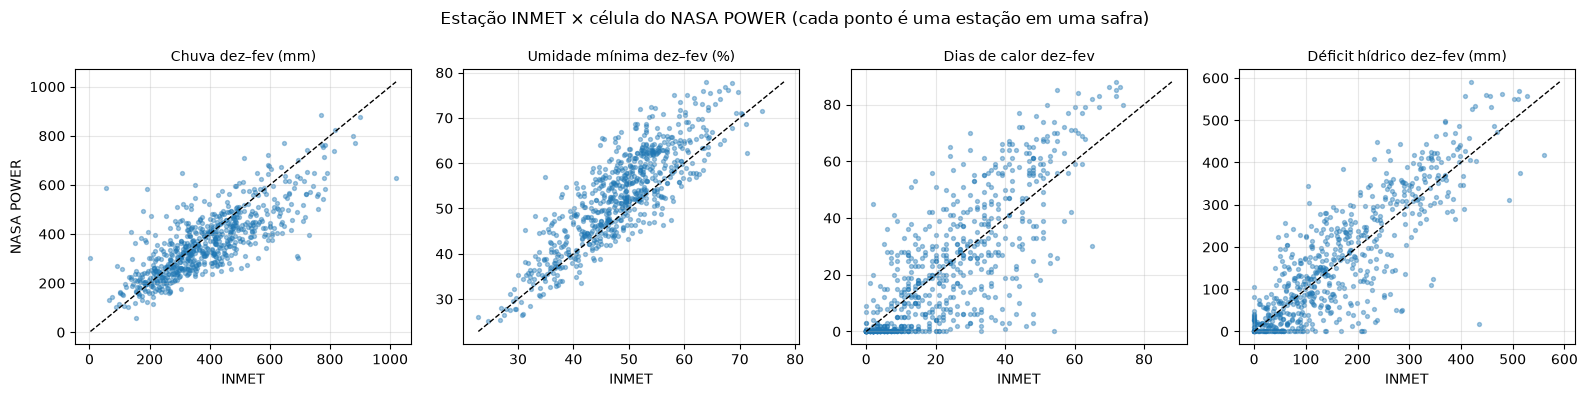

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, v, rotulo in zip(axes, ["chuva_dez_fev", "urmin_dez_fev", "dias_calor_dez_fev", "deficit_dez_fev"],
                         ["Chuva dez–fev (mm)", "Umidade mínima dez–fev (%)",
                          "Dias de calor dez–fev", "Déficit hídrico dez–fev (mm)"]):
    par = comp[[f"{v}_inmet", f"{v}_power"]].dropna()
    ax.scatter(par[f"{v}_inmet"], par[f"{v}_power"], s=8, alpha=0.4)
    lim = [min(par.min()), max(par.max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlabel("INMET")
    ax.set_title(rotulo, fontsize=10)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("NASA POWER")
fig.suptitle("Estação INMET × célula do NASA POWER (cada ponto é uma estação em uma safra)")
plt.tight_layout()
plt.show()

## 5. Patamar e bases de modelagem

Mesmo patamar e mesma linha de base da Etapa 4 (média móvel de 5 anos e média histórica),
calculados **só com as safras já publicadas na data da previsão**: em março de *Y*, a
última PAM/IBGE disponível é a de **Y−2** (constante `DEFASAGEM_PUBLICACAO`; ver seção 3
de `modelagem_etapa3.ipynb`). Para prever 2026, o patamar é a média de 2020–2024. Duas
bases:

- **INMET:** idêntica à da Etapa 4 (clima da estação mais próxima, com cobertura mínima);
- **NASA POWER:** clima da célula que contém o município. Como o NASA POWER não tem falhas,
  a base só perde linhas por falta de rendimento ou de patamar.

A coluna `tem_inmet` marca as linhas que também existem na base do INMET.

In [ ]:
rend = com_rendimento.pivot_table(index="ano_safra", columns="codigo_ibge_municipio", values=ALVO)
estado = rend.mean(axis=1)
partes = []
for ano in range(PRIMEIRA_SAFRA, int(rend.index.max()) + 1):
    ultima = ano - DEFASAGEM_PUBLICACAO   # última safra publicada em março de `ano`
    j5, todos = rend.loc[ultima - 4:ultima], rend.loc[:ultima]
    partes.append(pd.DataFrame({
        "ano_safra": ano,
        "patamar_mm5": j5.mean().where(j5.count() >= 3, estado.loc[ultima - 4:ultima].mean()),
        "base_media_hist": todos.mean().where(todos.count() >= 3, estado.loc[:ultima].mean()),
    }))
patamares = pd.concat(partes).rename_axis("codigo_ibge_municipio").reset_index()

OBRIGATORIAS = [ALVO, ONI, "patamar_mm5", "base_media_hist"] + CLIMA + VAR_HIDRICO
CHAVE = ["codigo_ibge_municipio", "ano_safra"]


def montar(clima):
    b = clima.merge(patamares, on=CHAVE, how="left").dropna(subset=OBRIGATORIAS)
    b = b[b["ano_safra"] >= PRIMEIRA_SAFRA].copy()
    b["desvio"] = b[ALVO] - b["patamar_mm5"]
    return b.reset_index(drop=True)


base_inmet = montar(painel.merge(clima_inmet, on=["codigo_estacao", "ano_safra"], how="left"))
base_power = montar(painel.merge(mapa[["codigo_ibge_municipio", "celula"]], on="codigo_ibge_municipio")
                    .merge(clima_power, on=["celula", "ano_safra"], how="left"))
chaves_inmet = pd.MultiIndex.from_frame(base_inmet[CHAVE])
base_power["tem_inmet"] = pd.MultiIndex.from_frame(base_power[CHAVE]).isin(chaves_inmet)

for nome, b in [("INMET", base_inmet), ("NASA POWER", base_power)]:
    print(f"{nome:<11} {len(b):>6} linhas | {b['codigo_ibge_municipio'].nunique()} municípios | "
          f"treino {(b['ano_safra'] <= ANO_CORTE).sum()} | teste {(b['ano_safra'] > ANO_CORTE).sum()}")
print(f"Linhas com rendimento a partir de {PRIMEIRA_SAFRA}: "
      f"{(com_rendimento['ano_safra'] >= PRIMEIRA_SAFRA).sum()}")
print(f"Linhas do NASA POWER que também estão na base do INMET: {base_power['tem_inmet'].sum()}")

In [8]:
# Onde estão as linhas novas
cobertura = pd.DataFrame({
    "INMET": base_inmet.merge(regioes, on="codigo_ibge_municipio").groupby("mesorregiao").size(),
    "NASA POWER": base_power.merge(regioes, on="codigo_ibge_municipio").groupby("mesorregiao").size(),
})
cobertura["aumento"] = cobertura["NASA POWER"] / cobertura["INMET"] - 1
cobertura.loc["Total"] = [len(base_inmet), len(base_power), len(base_power) / len(base_inmet) - 1]
cobertura.sort_values("NASA POWER", ascending=False).style.format(
    {"INMET": "{:.0f}", "NASA POWER": "{:.0f}", "aumento": "{:+.0%}"})

,INMET,NASA POWER,aumento
mesorregiao,,,
Total,5260,8651,+64%
Noroeste,2838,4536,+60%
Centro Oriental,554,1031,+86%
Nordeste,462,794,+72%
Metropolitana de Porto Alegre,486,768,+58%
Centro Ocidental,392,648,+65%
Sudeste,271,491,+81%
Sudoeste,257,383,+49%


## 6. Modelos

Os da Etapa 4 — linha de base (média histórica), **F** (OLS reduzida da Etapa 3), **H2**
(modelo final da Etapa 4: F + déficit hídrico + limiares de seca extrema) e **GB**
(Gradient Boosting com todas as variáveis climáticas, o ONI e o balanço hídrico) — e
quatro combinações de F e H2, testadas porque, com o NASA POWER, F e H2 empatavam:

| Combinação | Como é feita |
|---|---|
| **Média F + H2** | média simples das previsões de F e H2 |
| **Ridge** | as variáveis do H2 numa regressão com penalização (Ridge), que reduz o efeito da colinearidade entre déficit, chuva e umidade; a força da penalização é escolhida por validação cruzada dentro do treino |
| **FL — F + limiar de déficit** | as variáveis do F + só o termo de seca extrema do déficit hídrico, max(0, D − D80) |
| **F + limiar de umidade** | as variáveis do F + só o termo de seca extrema da umidade mínima, max(0, U20 − U) |

Médias, limiares e a penalização do Ridge são calculados só com o treino de cada rodada,
a partir da própria fonte de clima.

In [9]:
FEAT_F = ["chuva_out_nov_100", "chuva_dez_fev_c100", "chuva_dez_fev_c100_2", "chuva_mar_100",
          "dias_calor_dez_fev", "urmin_dez_fev"]
FEAT_H2 = FEAT_F + ["deficit_100", "limiar_urmin", "limiar_deficit_100"]
FEAT_FL = FEAT_F + ["limiar_deficit_100"]
FEAT_FU = FEAT_F + ["limiar_urmin"]
FEAT_GB = CLIMA + [ONI] + VAR_HIDRICO
FINAL = "FL - F + limiar de déficit"
PRINCIPAIS = ["Linha de base: média histórica", "F - Final Etapa 3", "H2 - Final Etapa 4",
              FINAL, "GB - Gradient Boosting"]
VARIACOES = ["F - Final Etapa 3", "H2 - Final Etapa 4", "Média F + H2", "Ridge (variáveis do H2)",
             FINAL, "F + limiar de umidade"]


def derivar(d, ref):
    d = d.copy()
    d["chuva_out_nov_100"] = d["chuva_out_nov"] / 100
    d["chuva_dez_fev_c100"] = (d["chuva_dez_fev"] - ref["chuva"]) / 100
    d["chuva_dez_fev_c100_2"] = d["chuva_dez_fev_c100"] ** 2
    d["chuva_mar_100"] = d["chuva_mar"] / 100
    d["deficit_100"] = d["deficit_dez_fev"] / 100
    d["limiar_urmin"] = (ref["urmin"] - d["urmin_dez_fev"]).clip(lower=0)
    d["limiar_deficit_100"] = (d["deficit_dez_fev"] - ref["deficit"]).clip(lower=0) / 100
    return d


def referencias(tr):
    return {"chuva": tr["chuva_dez_fev"].mean(),
            "urmin": tr["urmin_dez_fev"].quantile(PERCENTIL_LIMIAR),
            "deficit": tr["deficit_dez_fev"].quantile(1 - PERCENTIL_LIMIAR)}


def gb():
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500, min_samples_leaf=20,
                                         early_stopping=True, validation_fraction=0.1,
                                         random_state=SEED)


def prever_todos(tr, te):
    ref = referencias(tr)
    tr, te = derivar(tr, ref), derivar(te, ref)
    pat = te["patamar_mm5"].to_numpy()
    saida = {"Linha de base: média histórica": te["base_media_hist"].to_numpy()}
    for nome, feats in [("F - Final Etapa 3", FEAT_F), ("H2 - Final Etapa 4", FEAT_H2),
                        (FINAL, FEAT_FL), ("F + limiar de umidade", FEAT_FU)]:
        saida[nome] = pat + LinearRegression().fit(tr[feats], tr["desvio"]).predict(te[feats])
    saida["Média F + H2"] = (saida["F - Final Etapa 3"] + saida["H2 - Final Etapa 4"]) / 2
    ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25)))
    saida["Ridge (variáveis do H2)"] = pat + ridge.fit(tr[FEAT_H2], tr["desvio"]).predict(te[FEAT_H2])
    saida["GB - Gradient Boosting"] = pat + gb().fit(tr[FEAT_GB], tr["desvio"]).predict(te[FEAT_GB])
    return saida


def validar(base):
    # Devolve as previsões das duas validações (corte temporal e deixa uma safra de fora)
    ident = base[CHAVE + [ALVO, "patamar_mm5"] + (["tem_inmet"] if "tem_inmet" in base else [])]
    tr, te = base[base["ano_safra"] <= ANO_CORTE], base[base["ano_safra"] > ANO_CORTE]
    corte = ident.loc[te.index].assign(**prever_todos(tr, te))
    partes = []
    for ano in [a for a in sorted(base["ano_safra"].unique()) if a >= 2008]:
        tr, te = base[base["ano_safra"] != ano], base[base["ano_safra"] == ano]
        partes.append(ident.loc[te.index].assign(**prever_todos(tr, te)))
    return corte, pd.concat(partes)


def metricas(y, pred):
    return {"RMSE (kg/ha)": mean_squared_error(y, pred) ** 0.5,
            "MAE (kg/ha)": mean_absolute_error(y, pred),
            "R²": r2_score(y, pred),
            "Viés (kg/ha)": np.mean(pred - y)}


def resumo(cenarios, modelos=PRINCIPAIS):
    # cenarios: {nome: (previsões do corte, previsões do deixa uma safra de fora)}
    linhas = {}
    for nome, (corte, loyo) in cenarios.items():
        for m in modelos:
            c, l = metricas(corte[ALVO], corte[m]), metricas(loyo[ALVO], loyo[m])
            linhas[(nome, m)] = {("Corte 2021–2025", "linhas"): len(corte),
                                 ("Corte 2021–2025", "RMSE (kg/ha)"): c["RMSE (kg/ha)"],
                                 ("Corte 2021–2025", "R²"): c["R²"],
                                 ("Corte 2021–2025", "Viés (kg/ha)"): c["Viés (kg/ha)"],
                                 ("Deixa uma safra de fora", "linhas"): len(loyo),
                                 ("Deixa uma safra de fora", "RMSE (kg/ha)"): l["RMSE (kg/ha)"],
                                 ("Deixa uma safra de fora", "R²"): l["R²"],
                                 ("Deixa uma safra de fora", "Viés (kg/ha)"): l["Viés (kg/ha)"]}
    t = pd.DataFrame(linhas).T
    t.index.names = ["cenário", "modelo"]
    return t


def formatar(t):
    fmt = {c: ("{:.3f}" if c[1] == "R²" else "{:+.0f}" if c[1].startswith("Viés") else "{:.0f}")
           for c in t.columns}
    return t.style.format(fmt)


print("Modelos:", ", ".join(PRINCIPAIS + [v for v in VARIACOES if v not in PRINCIPAIS]))

Modelos: Linha de base: média histórica, F - Final Etapa 3, H2 - Final Etapa 4, FL - F + limiar de déficit, GB - Gradient Boosting, Média F + H2, Ridge (variáveis do H2), F + limiar de umidade


## 7. Resultados: INMET × NASA POWER

Três cenários, cada um avaliado nas duas validações:

1. **INMET** — referência; reproduz a Etapa 4 (mesmas linhas, mesmos números);
2. **NASA POWER, mesmas linhas do INMET** — comparação justa entre as duas fontes: mesmos
   municípios e safras, só muda a origem do clima;
3. **NASA POWER, todas as linhas** — cobertura ampliada; o modelo é treinado e avaliado
   com todos os municípios.

In [10]:
prev_inmet = validar(base_inmet)
prev_power_mesmas = validar(base_power[base_power["tem_inmet"]])
prev_power_todas = validar(base_power)

resultados = resumo({"1. INMET": prev_inmet,
                     "2. NASA POWER — mesmas linhas do INMET": prev_power_mesmas,
                     "3. NASA POWER — todas as linhas": prev_power_todas})
formatar(resultados)

### As linhas novas são previstas tão bem quanto as antigas?

O cenário 3 dividido em duas partes, com o mesmo modelo: as linhas que já existiam na
base do INMET e as linhas novas, que só entraram graças ao NASA POWER.

In [11]:
corte, loyo = prev_power_todas
partes = resumo({"3a. NASA POWER — linhas que já tinham INMET": (corte[corte["tem_inmet"]], loyo[loyo["tem_inmet"]]),
                 "3b. NASA POWER — linhas novas": (corte[~corte["tem_inmet"]], loyo[~loyo["tem_inmet"]])})
formatar(partes)

### Combinações de F e H2: qual é a melhor?

As seis variações lineares nos três cenários, ordenadas pela média do RMSE nas duas
validações (o critério de escolha do modelo final desde a Etapa 3). Foram testadas seis
variações nos mesmos dados; por isso, uma variação só deve substituir o F se for melhor de
forma consistente entre os cenários, e não por uma diferença isolada.

In [12]:
variacoes = resumo({"1. INMET": prev_inmet,
                    "2. NASA POWER — mesmas linhas do INMET": prev_power_mesmas,
                    "3. NASA POWER — todas as linhas": prev_power_todas}, modelos=VARIACOES)
variacoes[("Média", "RMSE (kg/ha)")] = (variacoes[("Corte 2021–2025", "RMSE (kg/ha)")]
                                       + variacoes[("Deixa uma safra de fora", "RMSE (kg/ha)")]) / 2
variacoes = variacoes.drop(columns=[c for c in variacoes.columns if c[1] in ("linhas", "Viés (kg/ha)")])
variacoes = variacoes.groupby(level="cenário", group_keys=False).apply(
    lambda t: t.sort_values(("Média", "RMSE (kg/ha)")))
formatar(variacoes)

## 8. Modelo final (FL) safra a safra

Rendimento médio do estado em cada safra, prevista sem ter sido vista (validação "deixa
uma safra de fora"): observado × modelo final da Etapa 4 (H2 com o clima do INMET) e
modelo final desta etapa (FL com o clima do NASA POWER, todas as linhas). A média estadual
de cada cenário usa as suas próprias linhas.

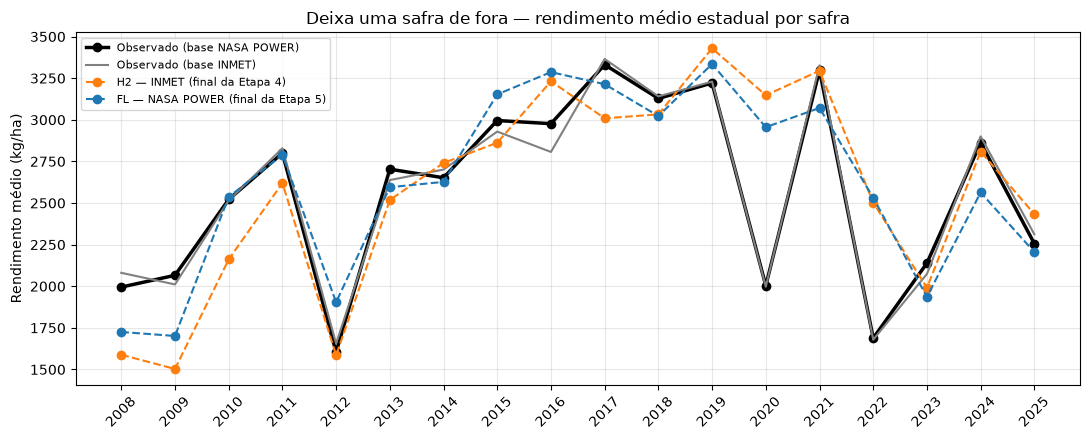

,MAE da média estadual (kg/ha),correlação com o observado
H2 — INMET,291.77,0.73
FL — NASA POWER,248.32,0.78


In [13]:
H2 = "H2 - Final Etapa 4"
estado_safra = pd.DataFrame({
    "observado (base INMET)": prev_inmet[1].groupby("ano_safra")[ALVO].mean(),
    "H2 — INMET": prev_inmet[1].groupby("ano_safra")[H2].mean(),
    "observado (base NASA POWER)": prev_power_todas[1].groupby("ano_safra")[ALVO].mean(),
    "FL — NASA POWER": prev_power_todas[1].groupby("ano_safra")[FINAL].mean(),
})

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(estado_safra.index, estado_safra["observado (base NASA POWER)"], "k-o", lw=2.5,
        label="Observado (base NASA POWER)")
ax.plot(estado_safra.index, estado_safra["observado (base INMET)"], "-", color="grey", lw=1.5,
        label="Observado (base INMET)")
ax.plot(estado_safra.index, estado_safra["H2 — INMET"], "--o", color="tab:orange",
        label="H2 — INMET (final da Etapa 4)")
ax.plot(estado_safra.index, estado_safra["FL — NASA POWER"], "--o", color="tab:blue",
        label="FL — NASA POWER (final da Etapa 5)")
ax.set_xticks(estado_safra.index)
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Rendimento médio (kg/ha)")
ax.set_title("Deixa uma safra de fora — rendimento médio estadual por safra")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

erro_estado = pd.DataFrame({
    nome: {"MAE da média estadual (kg/ha)": (estado_safra[prev] - estado_safra[obs]).abs().mean(),
           "correlação com o observado": estado_safra[prev].corr(estado_safra[obs])}
    for nome, prev, obs in [("H2 — INMET", "H2 — INMET", "observado (base INMET)"),
                            ("FL — NASA POWER", "FL — NASA POWER", "observado (base NASA POWER)")]}).T
erro_estado.round(2)

### As secas severas

Mesma medida da Etapa 4 (seção 10): desvio médio estadual em relação ao patamar nas quatro
maiores quebras, observado × previsto, e a fração da quebra que o modelo captou: H2 com o
INMET (final da Etapa 4), e F e FL com o NASA POWER (para ver o efeito do limiar).

In [14]:
def quebras(loyo, modelo):
    d = loyo.assign(observado=loyo[ALVO] - loyo["patamar_mm5"], previsto=loyo[modelo] - loyo["patamar_mm5"])
    s = d.groupby("ano_safra")[["observado", "previsto"]].mean().loc[[2012, 2020, 2022, 2023]]
    s["% da quebra captada"] = s["previsto"] / s["observado"]
    return s


secas = pd.concat({"H2 — INMET": quebras(prev_inmet[1], H2),
                   "F — NASA POWER": quebras(prev_power_todas[1], "F - Final Etapa 3"),
                   "FL — NASA POWER": quebras(prev_power_todas[1], FINAL)}, axis=1)
secas.style.format("{:.0f}").format("{:.0%}", subset=[c for c in secas.columns if c[1].startswith("%")])

## 9. Erro por mesorregião

Erro relativo (MAE como % do rendimento médio) na validação "deixa uma safra de fora":
H2 com o INMET (final da Etapa 4) e FL com o NASA POWER em todas as linhas (final desta
etapa).

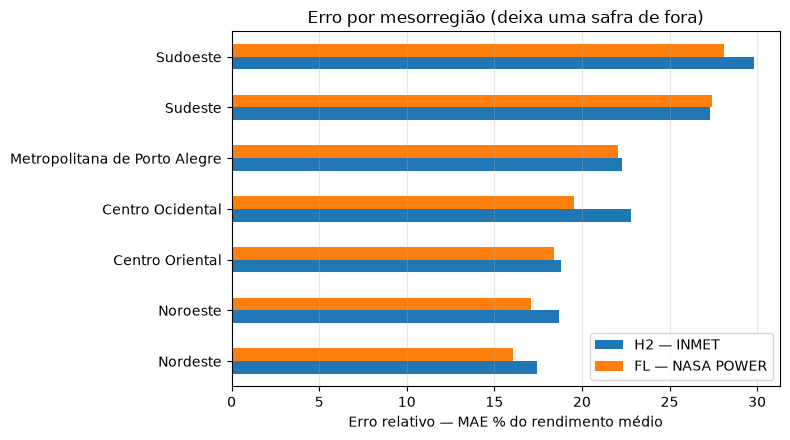

In [15]:
def erro_regiao(loyo, modelo):
    d = loyo.merge(regioes, on="codigo_ibge_municipio", how="left")
    d["erro_abs"] = (d[modelo] - d[ALVO]).abs()
    g = d.groupby("mesorregiao")
    return pd.DataFrame({"linhas": g.size(), "MAE %": g["erro_abs"].mean() / g[ALVO].mean()})


por_regiao = pd.concat({"H2 — INMET": erro_regiao(prev_inmet[1], H2),
                        "FL — NASA POWER": erro_regiao(prev_power_todas[1], FINAL)}, axis=1)
por_regiao = por_regiao.sort_values(("FL — NASA POWER", "linhas"), ascending=False)
display(por_regiao.style.format("{:.0f}").format(
    "{:.1%}", subset=[c for c in por_regiao.columns if c[1] == "MAE %"]))

ax = por_regiao.xs("MAE %", axis=1, level=1).mul(100).sort_values("FL — NASA POWER").plot.barh(figsize=(8, 4.5))
ax.set_xlabel("Erro relativo — MAE % do rendimento médio")
ax.set_ylabel("")
ax.set_title("Erro por mesorregião (deixa uma safra de fora)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Coeficientes do modelo final (FL)

FL ajustado com todas as linhas de cada base, para comparar sinais e magnitudes entre o
INMET e o NASA POWER. O limiar de déficit é o percentil 80 da base inteira (nas validações,
ele é recalculado só com o treino de cada rodada). Mesma ressalva das etapas anteriores
sobre os p-valores (linhas da mesma safra são correlacionadas).

In [16]:
def tabela_ols(modelo, X, y):
    Xc = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
    beta = np.r_[modelo.intercept_, modelo.coef_]
    residuos = y.to_numpy() - Xc @ beta
    gl = len(y) - Xc.shape[1]
    ep = np.sqrt(np.diag(residuos @ residuos / gl * np.linalg.inv(Xc.T @ Xc)))
    t = beta / ep
    return pd.DataFrame({"coeficiente": beta, "erro_padrao": ep, "t": t,
                         "p_valor": 2 * stats.t.sf(np.abs(t), gl)},
                        index=["intercepto"] + list(X.columns))


coefs = {}
for nome, b in [("INMET", base_inmet), ("NASA POWER", base_power)]:
    ref = referencias(b)
    completa = derivar(b, ref)
    ols = LinearRegression().fit(completa[FEAT_FL], completa["desvio"])
    coefs[nome] = tabela_ols(ols, completa[FEAT_FL], completa["desvio"])[["coeficiente", "p_valor"]]
    print(f"{nome}: chuva média de dez–fev = {ref['chuva']:.0f} mm | "
          f"limiar de déficit (percentil 80) = {ref['deficit']:.0f} mm")
pd.concat(coefs, axis=1).round(3)

INMET: chuva média de dez–fev = 417 mm | limiar de déficit (percentil 80) = 243 mm
NASA POWER: chuva média de dez–fev = 370 mm | limiar de déficit (percentil 80) = 287 mm


INMET          NASA POWER        
                     coeficiente p_valor coeficiente p_valor
intercepto               -973.30    0.00     -762.15    0.00
chuva_out_nov_100          -6.79    0.17      -26.49    0.00
chuva_dez_fev_c100        136.85    0.00      377.80    0.00
chuva_dez_fev_c100_2      -17.93    0.00      -82.72    0.00
chuva_mar_100              76.39    0.00        3.01    0.80
dias_calor_dez_fev         -0.23    0.75        3.80    0.00
urmin_dez_fev              23.72    0.00       19.55    0.00
limiar_deficit_100       -473.16    0.00     -257.87    0.00

## 11. Figuras para o artigo

Três figuras do modelo final (FL com o NASA POWER), salvas em `artigo/latex/figuras/` no
lugar das versões das Etapas 3 e 4 (modelos F e H2 com o INMET):

- **Figura 4** — contribuição de cada fator climático por safra. Para um modelo linear, o
  valor SHAP de uma variável é coeficiente × (valor − média) (Lundberg e Lee, 2017), como na
  seção 11 da Etapa 3. Modelo ajustado com todas as linhas; os dois termos da chuva de
  dez–fev são somados num único fator.
- **Figura 5** — desvio médio estadual em relação ao patamar, por safra, na validação
  "deixa uma safra de fora": observado, F e FL.
- **Figura 6** — erro relativo por mesorregião nas duas validações.

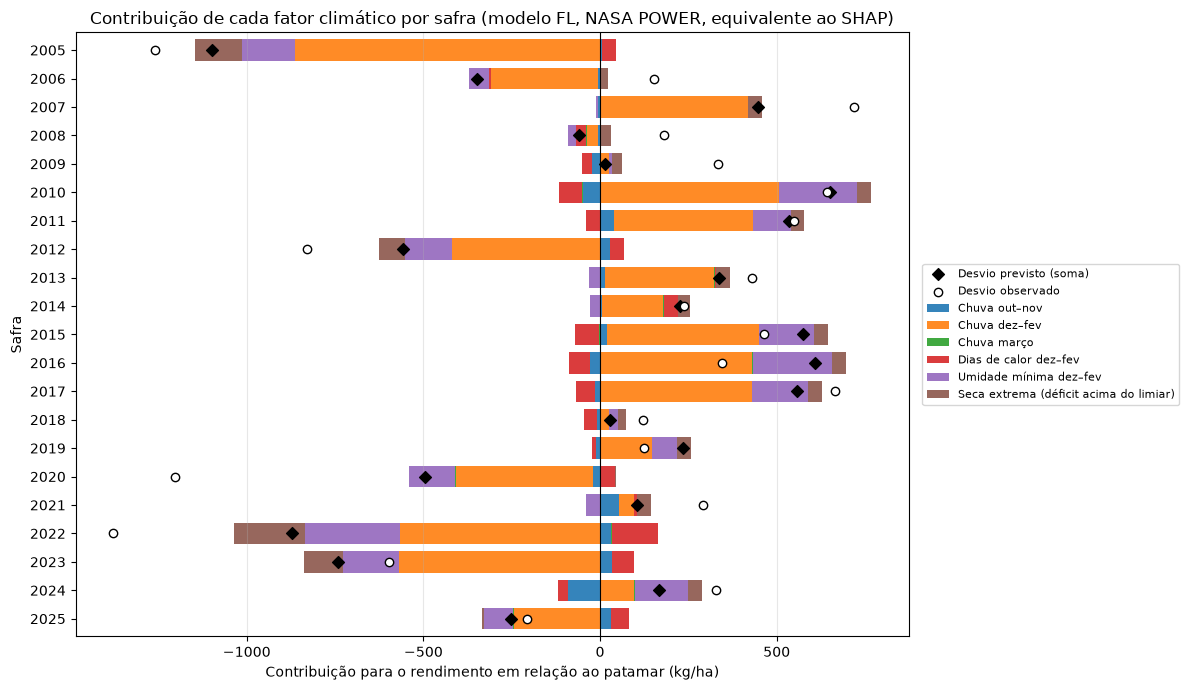

Importância média (média do |contribuição|, kg/ha):
Chuva dez–fev                            376.00
Umidade mínima dez–fev                   133.00
Dias de calor dez–fev                     66.00
Seca extrema (déficit acima do limiar)    65.00
Chuva out–nov                             30.00
Chuva março                                1.00


In [17]:
FIGDIR = "../artigo/latex/figuras"

# Figura 4: contribuição de cada fator (SHAP do modelo linear)
ref = referencias(base_power)
completa = derivar(base_power, ref)
fl = LinearRegression().fit(completa[FEAT_FL], completa["desvio"])
contrib = completa[FEAT_FL].sub(completa[FEAT_FL].mean()).mul(pd.Series(fl.coef_, index=FEAT_FL))
FATORES = {"Chuva out–nov": ["chuva_out_nov_100"],
           "Chuva dez–fev": ["chuva_dez_fev_c100", "chuva_dez_fev_c100_2"],
           "Chuva março": ["chuva_mar_100"],
           "Dias de calor dez–fev": ["dias_calor_dez_fev"],
           "Umidade mínima dez–fev": ["urmin_dez_fev"],
           "Seca extrema (déficit acima do limiar)": ["limiar_deficit_100"]}
contrib = pd.DataFrame({f: contrib[cols].sum(axis=1) for f, cols in FATORES.items()})
por_safra_contrib = contrib.groupby(completa["ano_safra"]).mean()
por_safra_contrib["Desvio previsto"] = por_safra_contrib[list(FATORES)].sum(axis=1)
por_safra_contrib["Desvio observado"] = ((completa["desvio"] - completa["desvio"].mean())
                                         .groupby(completa["ano_safra"]).mean())

fig, ax = plt.subplots(figsize=(12, 7))
por_safra_contrib[list(FATORES)].plot.barh(stacked=True, ax=ax, width=0.75, alpha=0.9)
y = np.arange(len(por_safra_contrib))
ax.scatter(por_safra_contrib["Desvio previsto"], y, marker="D", color="k", zorder=3,
           label="Desvio previsto (soma)")
ax.scatter(por_safra_contrib["Desvio observado"], y, marker="o", facecolor="white",
           edgecolor="k", zorder=3, label="Desvio observado")
ax.axvline(0, color="k", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("Contribuição para o rendimento em relação ao patamar (kg/ha)")
ax.set_ylabel("Safra")
ax.set_title("Contribuição de cada fator climático por safra (modelo FL, NASA POWER, equivalente ao SHAP)")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
fig.savefig(f"{FIGDIR}/fig4_contribuicao_fatores.png", dpi=150)
plt.show()

importancia_media = contrib.abs().mean().sort_values(ascending=False)
print("Importância média (média do |contribuição|, kg/ha):")
print(importancia_media.round(0).to_string())

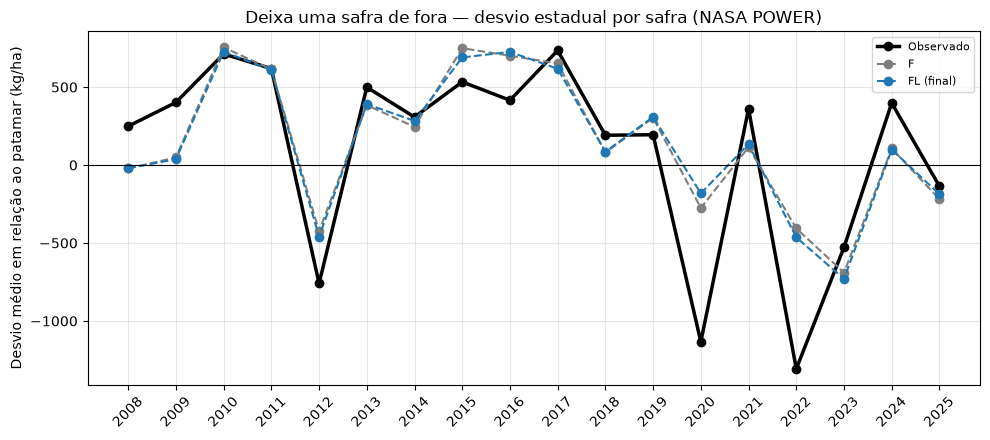

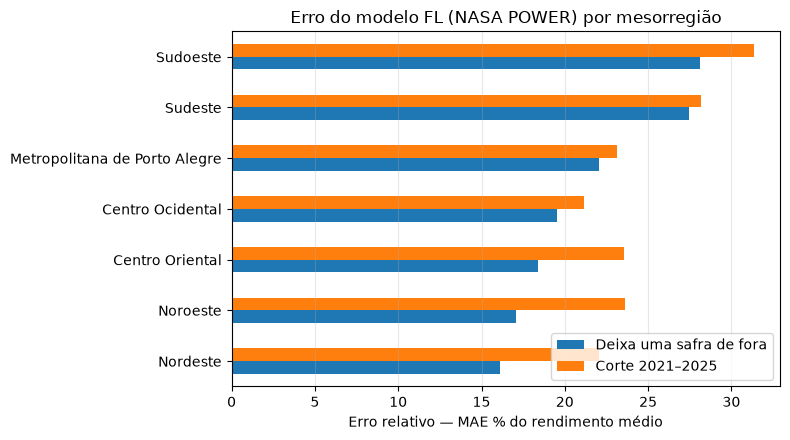

Figuras 4, 5 e 6 salvas em ../artigo/latex/figuras


,Deixa uma safra de fora,Corte 2021–2025
mesorregiao,,
Centro Ocidental,19.50,21.20
Centro Oriental,18.40,23.60
Metropolitana de Porto Alegre,22.00,23.20
Nordeste,16.10,22.00
Noroeste,17.10,23.60
Sudeste,27.40,28.20
Sudoeste,28.10,31.30


In [18]:
# Figura 5: desvio estadual por safra (deixa uma safra de fora)
loyo = prev_power_todas[1]
desvios = pd.DataFrame({"Observado": loyo[ALVO] - loyo["patamar_mm5"],
                        "F - Final Etapa 3": loyo["F - Final Etapa 3"] - loyo["patamar_mm5"],
                        FINAL: loyo[FINAL] - loyo["patamar_mm5"],
                        "ano_safra": loyo["ano_safra"]}).groupby("ano_safra").mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(desvios.index, desvios["Observado"], "k-o", lw=2.5, label="Observado")
ax.plot(desvios.index, desvios["F - Final Etapa 3"], "--o", color="tab:grey", label="F")
ax.plot(desvios.index, desvios[FINAL], "--o", color="tab:blue", label="FL (final)")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(desvios.index)
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Desvio médio em relação ao patamar (kg/ha)")
ax.set_title("Deixa uma safra de fora — desvio estadual por safra (NASA POWER)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(f"{FIGDIR}/fig5_secas_desvio_por_safra.png", dpi=150)
plt.show()

# Figura 6: erro relativo por mesorregião, nas duas validações
regiao_fl = pd.DataFrame({"Deixa uma safra de fora": erro_regiao(prev_power_todas[1], FINAL)["MAE %"],
                          "Corte 2021–2025": erro_regiao(prev_power_todas[0], FINAL)["MAE %"]})
fig, ax = plt.subplots(figsize=(8, 4.5))
regiao_fl.sort_values("Deixa uma safra de fora").mul(100).plot.barh(ax=ax)
ax.set_xlabel("Erro relativo — MAE % do rendimento médio")
ax.set_ylabel("")
ax.set_title("Erro do modelo FL (NASA POWER) por mesorregião")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
fig.savefig(f"{FIGDIR}/fig6_erro_por_mesorregiao.png", dpi=150)
plt.show()
print("Figuras 4, 5 e 6 salvas em", FIGDIR)
regiao_fl.mul(100).round(1)

## 12. Conclusões da Etapa 5

> **Atenção (2026-10-26):** os números desta seção vêm da execução de 23/10, com o patamar
> calculado até Y−1 (dado que ainda não estaria publicado em março). O código agora usa
> Y−2; reexecutar o notebook e atualizar esta seção, inclusive a escolha do modelo final
> (item 4) e a comparação com a Etapa 4 (item 5), cujos valores do H2 com o INMET passam a
> ser 870 e 706 kg/ha.

**1. O NASA POWER concorda bem com o INMET (seção 4).** Comparando cada estação com a
célula que a contém, a correlação entre safras fica entre 0,78 e 0,89 para quase todas as
variáveis (chuva por subperíodo, dias de calor, temperatura máxima, umidade mínima, déficit
hídrico) e entre 0,74 e 0,94 na média estadual de cada safra. A exceção é a maior
sequência de dias secos (0,53), mais sensível a chuvas pequenas. Diferenças de nível: o NASA
POWER tem ~6% menos chuva em dez–fev e umidade mínima ~4 pontos maior (estimada pelo
ponto de orvalho, FAO-56), o que não prejudica o modelo, treinado com a própria fonte.

**2. A cobertura subiu 64%:** de 5.260 para 8.651 pares município–safra (450 municípios),
ou seja, **todas** as linhas com rendimento a partir de 2005. O ganho é em todas as
mesorregiões (+49% a +86%).

**3. Nas mesmas linhas, o clima do NASA POWER prevê melhor que o do INMET (cenário 2).** O
RMSE cai em todos os modelos lineares — por exemplo, o H2 vai de 740 para 700 kg/ha no
corte temporal e de 684 para 656 kg/ha no "deixa uma safra de fora". Uma explicação
provável é que a célula do NASA POWER (~50 km) representa a média da área do município
melhor que uma estação pontual, às vezes a dezenas de quilômetros, e não tem falhas a
preencher.

**4. Novo modelo final: FL = F + limiar de seca extrema do déficit hídrico.** Com o NASA
POWER, F e H2 empataram (RMSE médio de 702 e 705 kg/ha). Das seis combinações testadas
(seção 7), o FL foi o melhor ou o segundo melhor nos três cenários — inclusive com o INMET,
onde também supera o H2 —, o que indica um ganho consistente e não um acaso de um único
teste. O FL acrescenta ao F um único termo, max(0, D − D80), que vale zero em safras
normais e só atua quando o déficit hídrico de dez–fev passa do nível das 20% safras mais
secas do treino. A média de F e H2 e o Ridge não melhoraram em relação ao F.

| Modelo final, NASA POWER, todas as linhas | Corte 2021–2025 | Deixa uma safra de fora |
|---|---|---|
| RMSE (kg/ha): F → FL | 765 → **739** (−3,4%) | 638 → **638** |
| R²: F → FL | 0,29 → **0,34** | 0,38 → **0,38** |
| Contra a linha de base (média histórica) | −16% | −28% |

O ganho está no período 2021–2025, que teve as secas mais fortes da série; no "deixa uma
safra de fora" o FL empata com o F. Também é nas linhas novas que ele mais ajuda (RMSE de
856 contra 910 kg/ha do F no corte temporal). O resultado explica por que o H2 não
ganhava: o termo de déficit "normal" repete a informação da chuva e da umidade de dez–fev,
e o que acrescenta é só o limiar — a perda acelera quando a seca passa de um ponto.

**5. Comparação com o modelo final da Etapa 4 (H2 com o INMET).** Nas mesmas linhas, o FL
com o NASA POWER erra menos (698 × 740 kg/ha no corte temporal e 651 × 684 kg/ha no "deixa
uma safra de fora"), e ainda cobre 64% mais linhas. Na média estadual por safra, o erro
cai de 292 para 248 kg/ha e a correlação com o observado sobe de 0,73 para 0,78.

**6. Secas severas (seção 8):** com o FL e o NASA POWER, a quebra de 2023 continua captada
por inteiro, a de 2022 fica em ~35% (36% com o H2 e o INMET), a de 2020 passa de 3% para
16% e a de 2012 cai de ~100% para ~61%. As secas extremas continuam sendo o principal
limite do modelo.

**7. Erro por mesorregião (seção 9):** igual ou menor com o FL e o NASA POWER em quase
todas as regiões, com o menor erro no Nordeste (16,1%) e no Noroeste (17,1%) e o maior no
Sudeste e Sudoeste (~27–28%), o mesmo padrão das etapas anteriores.

**8. Coeficientes do FL com o NASA POWER (seção 10):** chuva de dez–fev +378 kg/ha a cada
100 mm acima da média (~370 mm), com ganho decrescente; umidade mínima de dez–fev +20 kg/ha
por ponto percentual; e **−258 kg/ha a cada 100 mm de déficit acima de ~287 mm**, a perda
adicional da seca extrema. Os efeitos pequenos (chuva de out–nov, chuva de março e dias de
calor) mudam de sinal ou perdem significância entre as fontes e não devem ser
interpretados isoladamente.

**9. Fatores mais importantes (seção 11, figura 4):** em média, a chuva de dez–fev move a
previsão em ~376 kg/ha, a umidade mínima de dez–fev em ~133 kg/ha, e os dias de calor e o
termo de seca extrema em ~65 kg/ha cada; chuva de out–nov (~30) e de março (~1) quase não
pesam. O período de floração e enchimento de grãos concentra praticamente todo o efeito do
clima, como nas etapas anteriores. O termo de seca extrema só atua nas safras mais secas
(2005, 2012, 2022 e 2023). Os dias de calor aparecem com contribuição positiva em safras
quentes (por exemplo, 2022), o que não tem sentido agronômico: é efeito da colinearidade
com a umidade mínima, que já capta o verão seco.

**Ressalva:** a escolha do FL foi feita depois de testar seis variações nos mesmos dados, o
que deve ser declarado no artigo. O ganho sobre o F é modesto (~2% no RMSE médio), mas
consistente nos três cenários e nas duas fontes de clima.